# Imports

In [1]:
from pathlib import Path

import numpy as np
import scipy.io as sio
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch

plt.rcParams["figure.dpi"] = 110

# find or download the data

In [2]:
REPO_ID = "danaroth/indian_pines"
FILES = ["Indian_pines_corrected.mat", "Indian_pines_gt.mat"]
SUBDIRS = ["data/raw/indian_pines", "data/indian_pines", "Data/indian_pines"]

REPO_ROOT = Path(".") if Path("notebooks").is_dir() else Path("..")
candidates = [REPO_ROOT / s for s in SUBDIRS]

data_dir = next((d for d in candidates if all((d / f).exists() for f in FILES)), None)

if data_dir is None:
    from huggingface_hub import hf_hub_download

    data_dir = candidates[0]
    data_dir.mkdir(parents=True, exist_ok=True)
    for f in FILES:
        hf_hub_download(repo_id=REPO_ID, filename=f, repo_type="dataset", local_dir=str(data_dir))

print("Using data from:", data_dir)

Using data from: ..\data\raw\indian_pines


# load the cube and ground truth

In [3]:
cube = sio.loadmat(str(data_dir / "Indian_pines_corrected.mat"))["indian_pines_corrected"]
gt = sio.loadmat(str(data_dir / "Indian_pines_gt.mat"))["indian_pines_gt"]

H, W, B = cube.shape
print("cube:", cube.shape, cube.dtype)
print("gt:  ", gt.shape, gt.dtype)
assert gt.shape == (H, W), "cube and ground truth do not line up"

cube: (145, 145, 200) uint16
gt:   (145, 145) uint8


# NumPy axes

In [4]:
band_img = cube[:, :, 50]        # one band over the whole scene     -> (H, W)
spectrum = cube[72, 72, :]       # one pixel across all bands        -> (B,)
patch = cube[10:20, 10:20, :]    # a small spatial window, all bands -> (10, 10, B)
print("band image :", band_img.shape)
print("pixel spectrum:", spectrum.shape)
print("patch      :", patch.shape)

print()
print("mean over axis 0     :", cube.mean(axis=0).shape)       # collapses rows
print("mean over axis 2     :", cube.mean(axis=2).shape)       # collapses bands -> brightness image
print("mean over axes (0, 1):", cube.mean(axis=(0, 1)).shape)  # scene-average spectrum

band image : (145, 145)
pixel spectrum: (200,)
patch      : (10, 10, 200)

mean over axis 0     : (145, 200)
mean over axis 2     : (145, 145)
mean over axes (0, 1): (200,)


# dtypes and memory

In [5]:
print("dtype:", cube.dtype, "| bytes per value:", cube.itemsize)
print("value range:", cube.min(), "to", cube.max())
print()
print(f"as stored (uint16): {cube.nbytes / 1e6:.1f} MB")
print(f"as float32        : {cube.astype(np.float32).nbytes / 1e6:.1f} MB")
print(f"as float64        : {cube.astype(np.float64).nbytes / 1e6:.1f} MB")

# The uint16 pitfall: 5 - 10 should be -5, but unsigned integers wrap around.
a = np.array([5], dtype=np.uint16)
b = np.array([10], dtype=np.uint16)
print()
print("uint16  5 - 10 =", a - b)
print("float32 5 - 10 =", a.astype(np.float32) - b.astype(np.float32))

cube_f32 = cube.astype(np.float32)   # we use this float copy from now on

dtype: uint16 | bytes per value: 2
value range: 955 to 9604

as stored (uint16): 8.4 MB
as float32        : 16.8 MB
as float64        : 33.6 MB

uint16  5 - 10 = [65531]
float32 5 - 10 = [-5.]


# the two shapes we'll use all project

In [6]:
pixels = cube_f32.reshape(-1, B)             # (H*W, B)
chw = np.transpose(cube_f32, (2, 0, 1))      # (B, H, W)
print("pixels:", pixels.shape, "| chw:", chw.shape)

print("reshape round-trip is lossless:", np.array_equal(pixels.reshape(H, W, B), cube_f32))
print("transpose is a view (no copy) :", np.shares_memory(chw, cube_f32))

pixels: (21025, 200) | chw: (200, 145, 145)
reshape round-trip is lossless: True
transpose is a view (no copy) : True


# ground-truth classes

In [7]:
CLASS_NAMES = {
    0: "Unlabeled", 1: "Alfalfa", 2: "Corn-notill", 3: "Corn-mintill", 4: "Corn",
    5: "Grass-pasture", 6: "Grass-trees", 7: "Grass-pasture-mowed", 8: "Hay-windrowed",
    9: "Oats", 10: "Soybean-notill", 11: "Soybean-mintill", 12: "Soybean-clean",
    13: "Wheat", 14: "Woods", 15: "Buildings-Grass-Trees-Drives", 16: "Stone-Steel-Towers",
}

ids, counts = np.unique(gt, return_counts=True)
labelled = int((gt > 0).sum())
print(f"labelled pixels: {labelled} of {gt.size} ({100 * labelled / gt.size:.1f}%)\n")
for cid, n in zip(ids, counts):
    print(f"{int(cid):>2}  {CLASS_NAMES[int(cid)]:<30}{int(n):>6}")

labelled pixels: 10249 of 21025 (48.7%)

 0  Unlabeled                      10776
 1  Alfalfa                           46
 2  Corn-notill                     1428
 3  Corn-mintill                     830
 4  Corn                             237
 5  Grass-pasture                    483
 6  Grass-trees                      730
 7  Grass-pasture-mowed               28
 8  Hay-windrowed                    478
 9  Oats                              20
10  Soybean-notill                   972
11  Soybean-mintill                 2455
12  Soybean-clean                    593
13  Wheat                            205
14  Woods                           1265
15  Buildings-Grass-Trees-Drives     386
16  Stone-Steel-Towers                93


# figure saving function

In [11]:
FIG_DIR = REPO_ROOT / "reports" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)


def save_fig(fig, name):
    fig.savefig(FIG_DIR / name, dpi=150, bbox_inches="tight")
    print("saved", FIG_DIR / name)

# plot bands

saved ..\reports\figures\bands.png


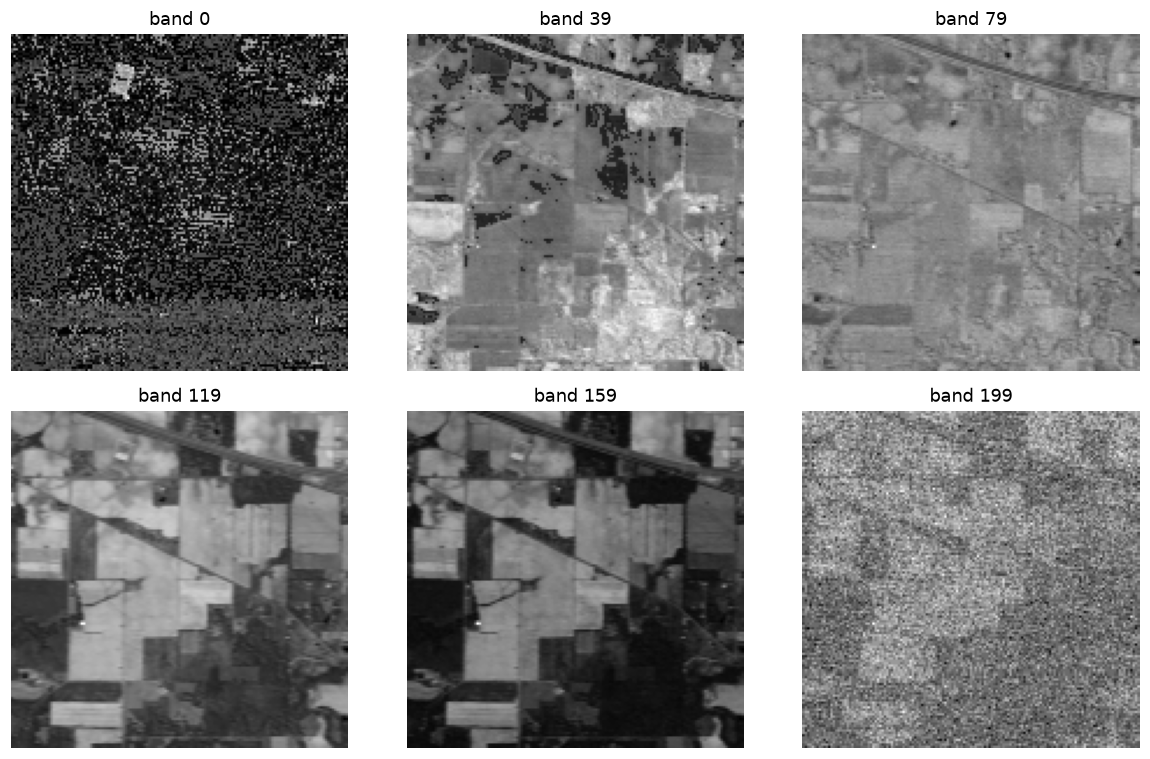

In [13]:

band_ids = np.linspace(0, B - 1, 6, dtype=int)

fig, axes = plt.subplots(2, 3, figsize=(11, 7))
for ax, b in zip(axes.ravel(), band_ids):
    ax.imshow(cube[:, :, b], cmap="gray")
    ax.set_title(f"band {b}")
    ax.axis("off")
fig.tight_layout()
save_fig(fig, "bands.png")
plt.show()

# false-colour preview and ground-truth map

saved ..\reports\figures\overview.png


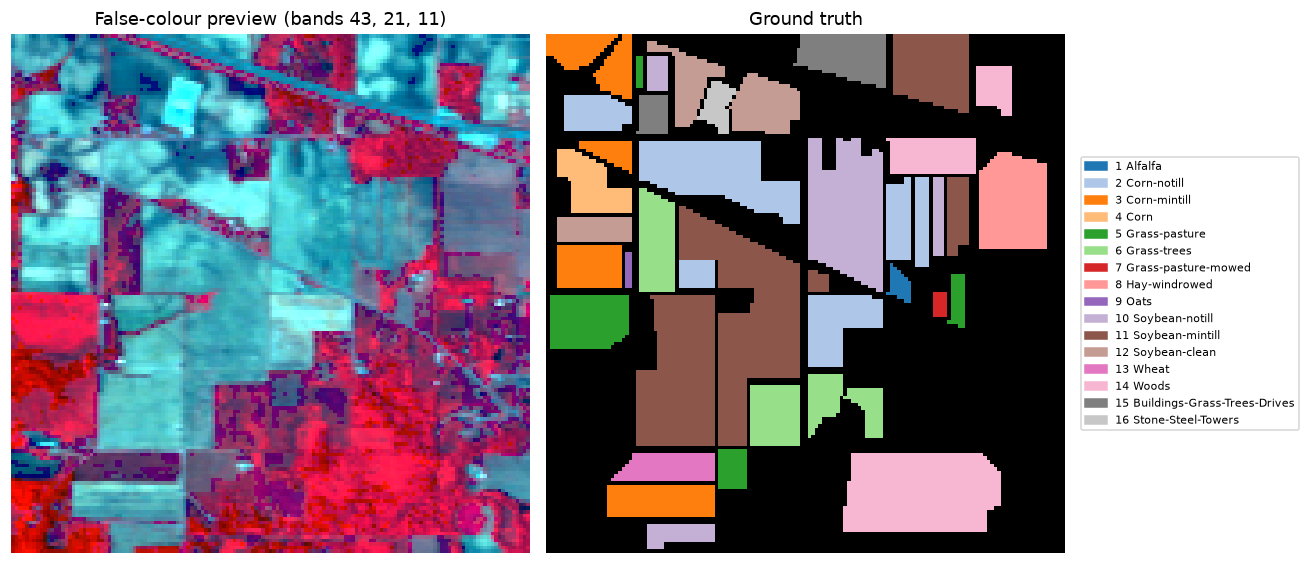

In [14]:
def false_colour(cube, bands=(43, 21, 11)):
    rgb = cube[:, :, list(bands)].astype(np.float32)
    lo, hi = np.percentile(rgb, (2, 98), axis=(0, 1))
    return np.clip((rgb - lo) / (hi - lo + 1e-9), 0, 1)


cmap = ListedColormap(np.vstack([[0, 0, 0, 1], plt.get_cmap("tab20")(np.arange(16))]))  # class 0 = black

fig, axes = plt.subplots(1, 2, figsize=(12, 6))
axes[0].imshow(false_colour(cube))
axes[0].set_title("False-colour preview (bands 43, 21, 11)")
axes[1].imshow(gt, cmap=cmap, vmin=0, vmax=16, interpolation="nearest")
axes[1].set_title("Ground truth")
handles = [Patch(color=cmap(i / 16), label=f"{i} {CLASS_NAMES[i]}") for i in range(1, 17)]
axes[1].legend(handles=handles, loc="center left", bbox_to_anchor=(1.02, 0.5), fontsize=7)
for ax in axes:
    ax.axis("off")
fig.tight_layout()
save_fig(fig, "overview.png")
plt.show()

# plot spectra

saved ..\reports\figures\class_spectra.png


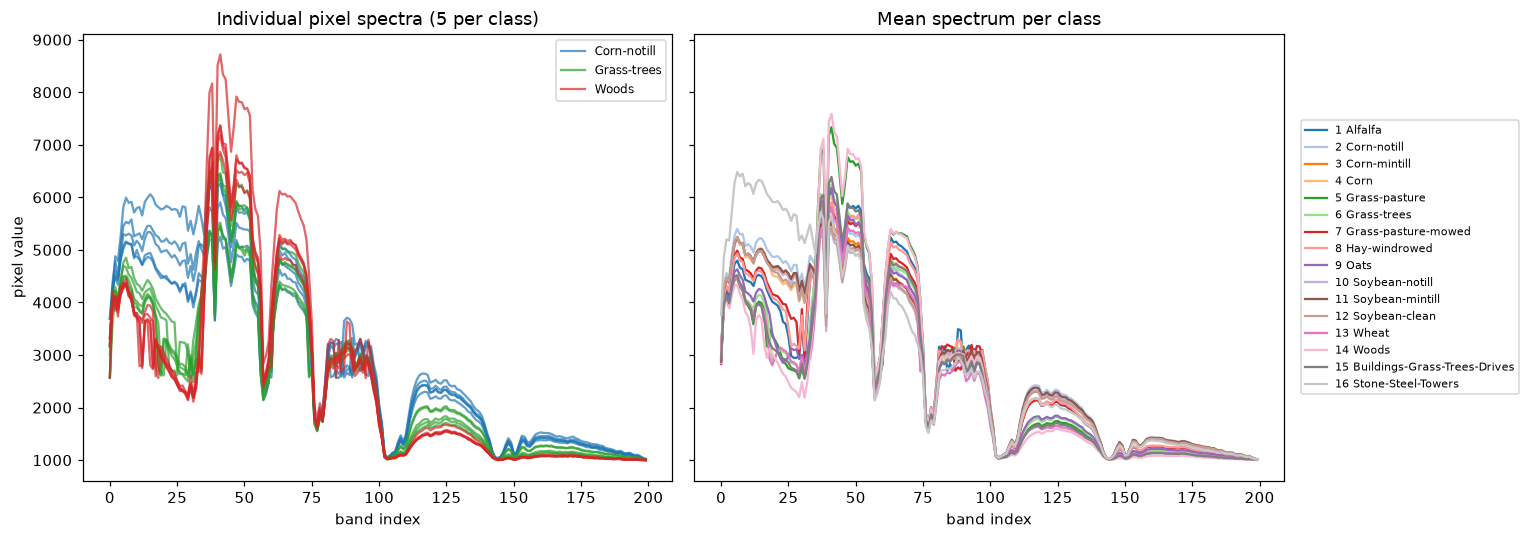

In [ ]:
rng = np.random.default_rng(0)
colours = plt.get_cmap("tab20")(np.arange(16))

fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)

strong = {2: "tab:blue", 6: "tab:green", 14: "tab:red"}  # Corn-notill, Grass-trees, Woods
for cid, colour in strong.items():
    rows, cols = np.where(gt == cid)
    for k, i in enumerate(rng.choice(len(rows), 5, replace=False)):
        axes[0].plot(cube[rows[i], cols[i], :], color=colour, alpha=0.7,
                     label=CLASS_NAMES[cid] if k == 0 else None)
axes[0].set_title("Individual pixel spectra (5 per class)")

for cid in range(1, 17):
    axes[1].plot(cube[gt == cid].mean(axis=0), color=colours[cid - 1], label=f"{cid} {CLASS_NAMES[cid]}")
axes[1].set_title("Mean spectrum per class")
axes[1].legend(loc="center left", bbox_to_anchor=(1.02, 0.5), fontsize=7)

for ax in axes:
    ax.set_xlabel("band index")
axes[0].set_ylabel("pixel value")
axes[0].legend(fontsize=8)
fig.tight_layout()
save_fig(fig, "class_spectra.png")
plt.show()

# Redundancy Figure

25 of 200 components explain 99% of the variance
saved ..\reports\figures\redundancy.png


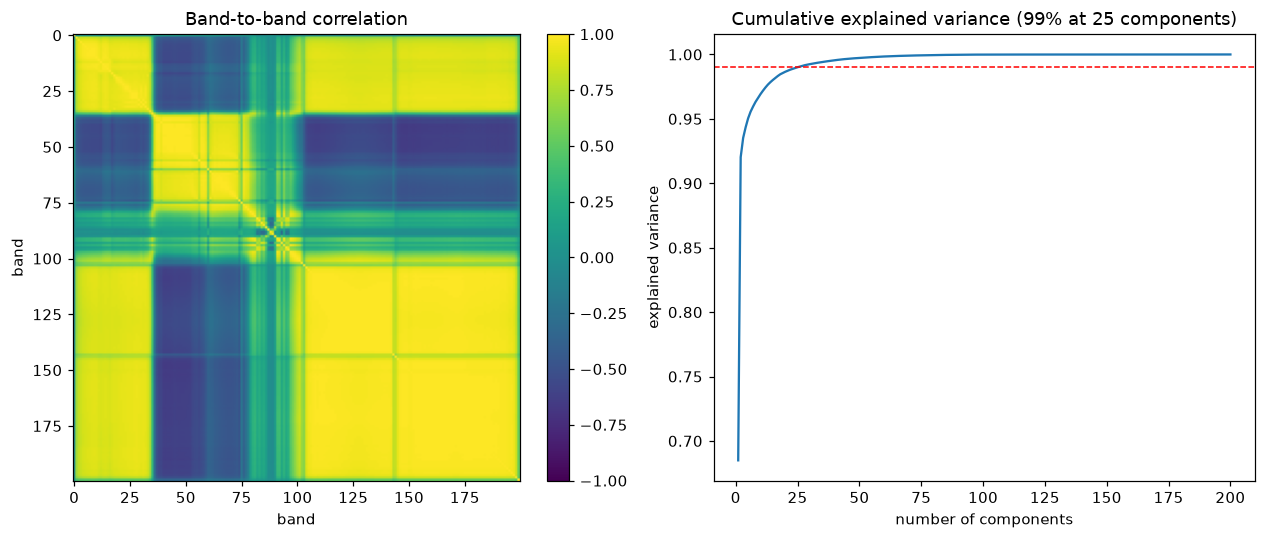

In [16]:
x = pixels.astype(np.float64)                      # (H*W, B) from Cell 6

with np.errstate(invalid="ignore", divide="ignore"):
    corr = np.nan_to_num(np.corrcoef(x, rowvar=False))   # band-to-band correlation

xc = x - x.mean(axis=0)
eig = np.linalg.eigvalsh(xc.T @ xc / (len(xc) - 1))[::-1]  # variance per component, largest first
cum = np.cumsum(eig / eig.sum())
n99 = int(np.searchsorted(cum, 0.99) + 1)
print(f"{n99} of {B} components explain 99% of the variance")

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
im = axes[0].imshow(corr, cmap="viridis", vmin=-1, vmax=1)
axes[0].set_title("Band-to-band correlation")
axes[0].set_xlabel("band")
axes[0].set_ylabel("band")
fig.colorbar(im, ax=axes[0], fraction=0.046)
axes[1].plot(np.arange(1, len(cum) + 1), cum)
axes[1].axhline(0.99, color="red", linestyle="--", linewidth=1)
axes[1].set_title(f"Cumulative explained variance (99% at {n99} components)")
axes[1].set_xlabel("number of components")
axes[1].set_ylabel("explained variance")
fig.tight_layout()
save_fig(fig, "redundancy.png")
plt.show()